# 06. RetinaNet (one-stage, anchor-based)

Одноетапний детектор з anchors: `retinanet_resnet50_fpn_v2` з torchvision, ваги натреновані на COCO. Протокол той самий, що в `05` (Faster R-CNN), щоб їх можна було порівняти напряму:
- train: 56 відео, кожен 5-й кадр (ті самі 4 868 кадрів, що в усіх моделях);
- val: 7 відео, усі кадри;
- вхід: довша сторона кадру 1280 px;
- 12 епох, SGD, warmup + косинус, той самий learning rate, batch 4, AMP;
- після кожної епохи mAP на кожному 5-му кадрі val, оцінюємо ваги найкращої епохи;
- оцінка: `COCOeval` з ignored regions як `iscrowd = 1` і лімітом 500 детекцій на кадр.

**Чим RetinaNet відрізняється від Faster R-CNN.** Немає першого етапу з proposals. Голова класифікації дивиться одразу на всі anchors (9 на кожну точку кожного рівня FPN, це сотні тисяч на кадр) і для кожного каже, якого він класу або що це фон. Майже всі anchors — фон, і звичайний loss "потонув" би в цих легких прикладах. Тому RetinaNet використовує **focal loss**: він зменшує вагу прикладів, які модель уже впевнено класифікує, і змушує вчитися на складних.

Anchor вважається позитивним для об'єкта, якщо їхній IoU ≥ 0.5, і фоном, якщо IoU < 0.4. Якщо в об'єкта немає жодного anchor з IoU ≥ 0.5, torchvision все одно робить позитивним його найкращий anchor, але для об'єкта в 10 px і anchor у 32 px їхній IoU лише ~0.1, тож такий об'єкт дає моделі дуже слабкий сигнал. Розділ 5 рахує, у скількох наших об'єктів є хоча б один anchor з IoU ≥ 0.5 при стандартних розмірах (від 32 px).

Налаштування тут стандартні (initial). Розміри anchors під наші дані (k-means з `01_eda`) і параметри focal loss будемо налаштовувати в наступному запуску.

Потрібно: GPU T4 і увімкнений Internet.

## 0. Налаштування

In [1]:
%pip install -q pycocotools

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import math
import random
import time
from functools import partial
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import DataLoader
from torchvision.io import ImageReadMode, decode_jpeg, read_file
from torchvision.models.detection import RetinaNet_ResNet50_FPN_V2_Weights, retinanet_resnet50_fpn_v2
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import box_iou
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

RUN_NAME = "retinanet_r50fpn_v2_1280"
IMG_SIZE = 1280
EPOCHS = 12
BATCH = 4
LR = 0.005
WARMUP_ITERS = 500
STEP = 5
MAX_TRAIN_HOURS = 6
WORKERS = 4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda")

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | GPU: Tesla T4


Дані шукаємо так само, як у попередніх ноутбуках.

In [3]:
ROOT = next(
    path.parent
    for pattern in ["*/test_images.csv", "*/*/test_images.csv", "*/*/*/test_images.csv"]
    for path in Path("/kaggle/input").glob(pattern)
)
OUT = Path("/kaggle/working")
print(ROOT)

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Дані

Рамки беремо з `annotations_coco.json`: вони вже в пікселях, а `category_id` 1–8 збігається з нумерацією torchvision (0 — фон). Ignored regions (`iscrowd = 1`) у тренування не йдуть, рамки з шириною чи висотою менше 1 px відкидаємо (на них torchvision падає).

Список кадрів train будуємо тим самим кодом, що в YOLO, і перевіряємо кількість, щоб протокол точно збігався.

In [4]:
def frame_list(split):
    return pl.DataFrame({"path": sorted(str(path) for path in (ROOT / split / "images").rglob("*.jpg"))}).with_columns(
        video=pl.col("path").str.split("/").list.get(-2)
    )


def frame_key(path):
    return "/".join(Path(path).parts[-2:])


def load_boxes(split):
    coco = json.loads((ROOT / split / "annotations_coco.json").read_text())
    key_by_id = {image["id"]: frame_key(image["file_name"]) for image in coco["images"]}
    boxes = {key: [] for key in key_by_id.values()}
    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        if not ann["iscrowd"] and w >= 1 and h >= 1:
            boxes[key_by_id[ann["image_id"]]].append((x, y, x + w, y + h, ann["category_id"]))
    return coco, boxes


train_frames = frame_list("train").filter((pl.int_range(pl.len()).over("video") % STEP) == 0)
val_frames = frame_list("val")
train_coco, train_boxes = load_boxes("train")
val_coco, val_boxes = load_boxes("val")
train_paths = train_frames["path"].to_list()
val_paths = val_frames["path"].to_list()

assert len(train_paths) == 4868 and len(val_paths) == 2846, (len(train_paths), len(val_paths))
print("train:", len(train_paths), "кадрів з", train_frames["video"].n_unique(), "відео;", sum(len(train_boxes[frame_key(path)]) for path in train_paths), "рамок")
print("val:", len(val_paths), "кадрів з", val_frames["video"].n_unique(), "відео")

train: 4868 кадрів з 56 відео; 222879 рамок
val: 2846 кадрів з 7 відео


Кадр читаємо як байти 0–255 (так його вчетверо дешевше передавати між процесами), у числа від 0 до 1 переводимо вже на GPU. Масштабування до 1280 і нормалізацію модель робить сама, і сама повертає рамки в пікселі оригінального кадру. Аугментація на train лише горизонтальне відзеркалення з імовірністю 0.5, як у `05`.

Замість окремого класу Dataset передаємо в DataLoader список шляхів, а читання робить `collate_fn`, тож воно все одно йде паралельно в 4 процесах.

In [5]:
def load_batch(paths, boxes, train):
    images, targets = [], []
    for path in paths:
        image = decode_jpeg(read_file(str(path)), mode=ImageReadMode.RGB)
        items = boxes.get(frame_key(path), []) if boxes is not None else []
        target_boxes = torch.tensor([item[:4] for item in items], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor([item[4] for item in items], dtype=torch.int64)
        if train and random.random() < 0.5:
            width = image.shape[-1]
            image = image.flip(-1)
            target_boxes = torch.stack([width - target_boxes[:, 2], target_boxes[:, 1], width - target_boxes[:, 0], target_boxes[:, 3]], dim=1)
        images.append(image)
        targets.append({"boxes": target_boxes, "labels": labels})
    return images, targets, paths


def to_device(images):
    return [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]


train_loader = DataLoader(
    train_paths,
    batch_size=BATCH,
    shuffle=True,
    num_workers=WORKERS,
    collate_fn=partial(load_batch, boxes=train_boxes, train=True),
    generator=torch.Generator().manual_seed(SEED),
    drop_last=True,
    pin_memory=True,
    persistent_workers=True,
)
images, targets, paths = next(iter(DataLoader(train_paths[:8], batch_size=4, num_workers=WORKERS, collate_fn=partial(load_batch, boxes=train_boxes, train=False))))
print(len(train_loader), "кроків на епоху |", [tuple(image.shape) for image in images], [len(target["boxes"]) for target in targets])

1217 кроків на епоху | [(3, 756, 1344), (3, 756, 1344), (3, 756, 1344), (3, 756, 1344)] [23, 23, 23, 23]


## 2. Модель

Беремо RetinaNet v2 з вагами COCO і замінюємо лише останній шар голови класифікації (`cls_logits`): 9 виходів замість 91 класу COCO. Чотири згорткові шари перед ним, голова рамок і решта мережі стартують з навчених ваг, так само як у Faster R-CNN замінюється лише останній шар.

Виходи голови рамок переводимо у fp32: інакше під AMP координати рамок округлюються до 1 px на кадрі 1280, а це помітно для об'єктів у 10 px.

Що змінено відносно налаштувань torchvision за замовчуванням:
- `min_size = max_size = 1280`: довша сторона 1280 px, як у `03_yolo_1280` і `05`;
- `detections_per_img = 500` і `score_thresh = 0.001`: як в інших моделях.

Anchors стандартні: на рівнях P3–P7 базові розміри 32, 64, 128, 256, 512 px, на кожному три масштаби (×1, ×1.26, ×1.59) і три пропорції (0.5, 1, 2), тобто 9 anchors на точку. Focal loss стандартний: α = 0.25, γ = 2.

In [6]:
model = retinanet_resnet50_fpn_v2(
    weights=RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1,
    min_size=IMG_SIZE,
    max_size=IMG_SIZE,
    score_thresh=0.001,
    detections_per_img=500,
)
num_anchors = model.anchor_generator.num_anchors_per_location()[0]
classification_head = RetinaNetClassificationHead(256, num_anchors, len(CLASSES) + 1, norm_layer=partial(torch.nn.GroupNorm, 32))
classification_head.conv = model.head.classification_head.conv
model.head.classification_head = classification_head
model.head.regression_head.register_forward_hook(lambda module, inputs, output: output.float())
model.to(DEVICE)

print("anchors по рівнях:", [tuple(round(size) for size in sizes) for sizes in model.anchor_generator.sizes], "| пропорції:", model.anchor_generator.aspect_ratios[0], "| на точку:", num_anchors)
print("параметрів:", round(sum(parameter.numel() for parameter in model.parameters()) / 1e6, 1), "млн")

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_v2_coco-5905b1c5.pth


100%|██████████| 146M/146M [00:00<00:00, 204MB/s]


anchors по рівнях: [(32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812)] | пропорції: (0.5, 1.0, 2.0) | на точку: 9
параметрів: 36.5 млн


## 3. Тренування

Голова класифікації RetinaNet оцінює кожен клас окремо (sigmoid). Наші мітки 1–8, тож вихід 0 ніколи не буває позитивним, але з низьким score він може потрапити в передбачення. Тому мітку 0 відкидаємо: інакше вона займала б місця з ліміту 500, а в сабміті з'явився б клас -1.

Оптимізатор і розклад такі самі, як у `05`: SGD з momentum 0.9 і weight decay 1e-4, learning rate 0.005, 500 кроків warmup, далі косинус. Для RetinaNet референсний learning rate у torchvision удвічі менший (0.0025 при batch 4), але ми тримаємо однаковий з Faster R-CNN, щоб протокол збігався. Норму градієнта обрізаємо до 10, батчі з нескінченним loss пропускаємо.

Статистики BatchNorm у backbone заморожуємо: при batch 4 вони дуже шумні й псують ваги, навчені на COCO (так само, як у `05`).

Після кожної епохи рахуємо mAP на кожному 5-му кадрі val і зберігаємо ваги найкращої епохи. Якщо після першої епохи видно, що 12 епох не вкладаються в `MAX_TRAIN_HOURS`, кількість епох зменшується, а косинус перебудовується під нову кількість.

RetinaNet має два лоси: `classification` (focal loss по всіх anchors) і `bbox_regression` (уточнення рамок позитивних anchors).

In [7]:
def predict(paths, batch_size=BATCH):
    loader = DataLoader(paths, batch_size=batch_size, num_workers=WORKERS, collate_fn=partial(load_batch, boxes=None, train=False), pin_memory=True)
    model.eval()
    results, total_time, timed_images = {}, 0.0, 0
    with torch.no_grad():
        for batch_index, (images, targets, batch_paths) in enumerate(loader):
            images = to_device(images)
            torch.cuda.synchronize()
            tick = time.perf_counter()
            outputs = model(images)
            torch.cuda.synchronize()
            if batch_index > 0:
                total_time += time.perf_counter() - tick
                timed_images += len(images)
            for path, output in zip(batch_paths, outputs):
                keep = output["labels"] > 0
                results[frame_key(path)] = (output["boxes"][keep].float().cpu(), output["scores"][keep].float().cpu(), output["labels"][keep].cpu())
    return results, 1000 * total_time / max(timed_images, 1)


val_id_by_key = {frame_key(image["file_name"]): image["id"] for image in val_coco["images"]}
ground_truth = COCO(str(ROOT / "val" / "annotations_coco.json"))


def to_coco_detections(results):
    return [
        {"image_id": val_id_by_key[key], "category_id": int(label), "bbox": [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2), round(float(y2 - y1), 2)], "score": round(float(score), 4)}
        for key, (boxes, scores, labels) in results.items()
        for (x1, y1, x2, y2), score, label in zip(boxes.tolist(), scores.tolist(), labels.tolist())
    ]


def coco_evaluate(detections, image_ids=None):
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes(detections), "bbox")
        evaluator.params.maxDets = [1, 100, 500]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def map_500(evaluator):
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    return float(np.mean(precision[precision > -1])) if (precision > -1).any() else 0.0


quick_val_paths = val_frames.filter((pl.int_range(pl.len()).over("video") % 5) == 0)["path"].to_list()
quick_val_ids = [val_id_by_key[frame_key(path)] for path in quick_val_paths]
print("швидка підвибірка val:", len(quick_val_paths), "кадрів")

loading annotations into memory...
Done (t=0.44s)
creating index...
index created!
швидка підвибірка val: 571 кадрів


In [8]:
parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(parameters, lr=LR, momentum=0.9, weight_decay=1e-4)
total_iters = EPOCHS * len(train_loader)


def lr_factor(step):
    if step < WARMUP_ITERS:
        return 0.001 + 0.999 * step / WARMUP_ITERS
    progress = (step - WARMUP_ITERS) / max(total_iters - WARMUP_ITERS, 1)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(progress, 1.0)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler("cuda")

history = []
best_map = -1.0
skipped_batches = 0
planned_epochs = EPOCHS
start = time.time()
epoch = 0
while epoch < planned_epochs:
    epoch += 1
    epoch_start = time.time()
    model.train()
    for module in model.backbone.modules():
        if isinstance(module, torch.nn.BatchNorm2d):
            module.eval()
    sums = {}
    steps = 0
    for images, targets, paths in train_loader:
        images = to_device(images)
        targets = [{key: value.to(DEVICE, non_blocking=True) for key, value in target.items()} for target in targets]
        with torch.autocast("cuda", dtype=torch.float16):
            losses = model(images, targets)
            loss = sum(losses.values())
        if not torch.isfinite(loss):
            skipped_batches += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, 10.0)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()
        for name, value in losses.items():
            sums[name] = sums.get(name, 0.0) + value.item()
        steps += 1

    results, _ = predict(quick_val_paths)
    quick = coco_evaluate(to_coco_detections(results), quick_val_ids)
    row = {
        "epoch": epoch,
        **{f"train/{name}": round(total / max(steps, 1), 4) for name, total in sums.items()},
        "val_mAP": round(map_500(quick), 4),
        "val_AP50": round(float(quick.stats[1]), 4),
        "lr": optimizer.param_groups[0]["lr"],
        "minutes": round((time.time() - epoch_start) / 60, 1),
        "gpu_gb": round(torch.cuda.max_memory_allocated() / 2**30, 1),
    }
    history.append(row)
    torch.save(model.state_dict(), OUT / f"{RUN_NAME}_last.pt")
    if row["val_mAP"] > best_map:
        best_map = row["val_mAP"]
        torch.save(model.state_dict(), OUT / f"{RUN_NAME}_best.pt")
    pl.DataFrame(history).write_csv(OUT / f"history_{RUN_NAME}.csv")

    elapsed_hours = (time.time() - start) / 3600
    if epoch == 1 and int(MAX_TRAIN_HOURS / elapsed_hours) < planned_epochs:
        planned_epochs = max(int(MAX_TRAIN_HOURS / elapsed_hours), 2)
        total_iters = planned_epochs * len(train_loader)
        print(f"епоха триває {elapsed_hours * 60:.0f} хв: скорочую розклад до {planned_epochs} епох, щоб вкластись у {MAX_TRAIN_HOURS} год")
    print(f"епоха {epoch}/{planned_epochs} | {row['minutes']} хв | " + " ".join(f"{name} {value:.3f}" for name, value in row.items() if name.startswith("train/")) + f" | quick mAP {row['val_mAP']:.4f} | AP50 {row['val_AP50']:.4f} | GPU {row['gpu_gb']} ГБ", flush=True)
    if epoch < planned_epochs and elapsed_hours + elapsed_hours / epoch > MAX_TRAIN_HOURS + 0.5:
        print(f"зупиняю після епохи {epoch}: наступна не вкладеться в {MAX_TRAIN_HOURS} год")
        break

train_hours = (time.time() - start) / 3600
print(f"тренування: {train_hours:.2f} год, епох: {len(history)}, пропущено батчів: {skipped_batches}, найкращий quick mAP: {best_map:.4f}")

епоха 1/12 | 12.0 хв | train/classification 0.364 train/bbox_regression 0.247 | quick mAP 0.1659 | AP50 0.3104 | GPU 4.8 ГБ
епоха 2/12 | 12.0 хв | train/classification 0.198 train/bbox_regression 0.229 | quick mAP 0.1853 | AP50 0.3467 | GPU 4.8 ГБ
епоха 3/12 | 12.0 хв | train/classification 0.173 train/bbox_regression 0.221 | quick mAP 0.1886 | AP50 0.3577 | GPU 4.8 ГБ
епоха 4/12 | 12.0 хв | train/classification 0.157 train/bbox_regression 0.215 | quick mAP 0.1993 | AP50 0.3716 | GPU 4.8 ГБ
епоха 5/12 | 12.0 хв | train/classification 0.145 train/bbox_regression 0.211 | quick mAP 0.1993 | AP50 0.3771 | GPU 4.8 ГБ
епоха 6/12 | 12.0 хв | train/classification 0.135 train/bbox_regression 0.207 | quick mAP 0.1991 | AP50 0.3777 | GPU 4.9 ГБ
епоха 7/12 | 12.0 хв | train/classification 0.128 train/bbox_regression 0.204 | quick mAP 0.1995 | AP50 0.3814 | GPU 4.9 ГБ
епоха 8/12 | 12.0 хв | train/classification 0.122 train/bbox_regression 0.201 | quick mAP 0.2026 | AP50 0.3803 | GPU 4.9 ГБ
епоха 9/

Криві навчання: два лоси і mAP на швидкій підвибірці val по епохах.

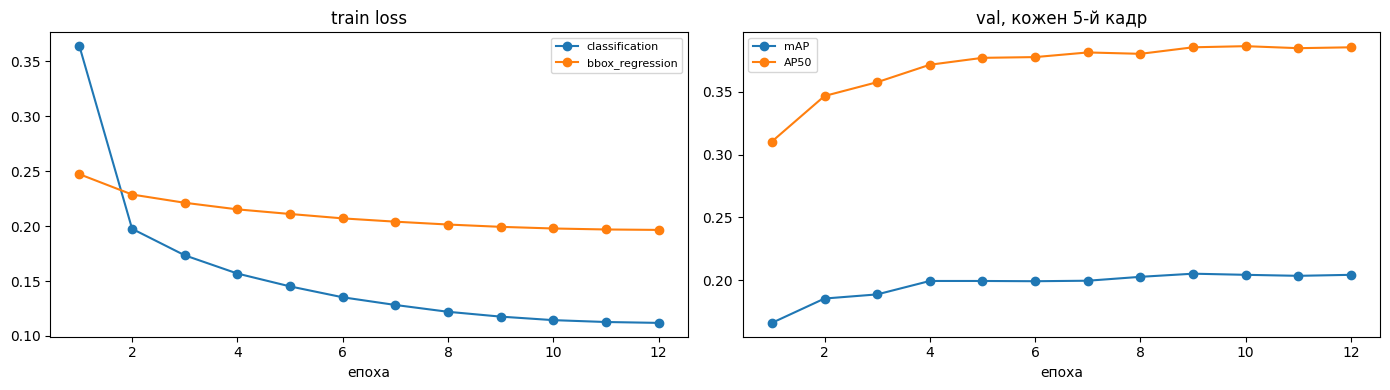

In [9]:
history_frame = pl.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name in [name for name in history_frame.columns if name.startswith("train/")]:
    axes[0].plot(history_frame["epoch"], history_frame[name], marker="o", label=name.removeprefix("train/"))
axes[0].set_title("train loss")
axes[1].plot(history_frame["epoch"], history_frame["val_mAP"], marker="o", label="mAP")
axes[1].plot(history_frame["epoch"], history_frame["val_AP50"], marker="o", label="AP50")
axes[1].set_title("val, кожен 5-й кадр")
for ax in axes:
    ax.set_xlabel("епоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Оцінка на всіх кадрах val

Беремо ваги найкращої епохи і передбачаємо всі кадри val у повній точності (fp32), як і в інших моделях. Швидкість: час проходу моделі разом з масштабуванням і NMS на кадр, batch 4, перший батч не рахуємо.

In [10]:
model.load_state_dict(torch.load(OUT / f"{RUN_NAME}_best.pt", map_location=DEVICE))
val_results, ms_per_image = predict(val_paths)
detections = to_coco_detections(val_results)
(OUT / f"val_predictions_{RUN_NAME}.json").write_text(json.dumps(detections))
evaluator = coco_evaluate(detections)
evaluator.summarize()
print(len(detections), "детекцій на", len(val_results), "кадрах;", f"{ms_per_image:.1f} ms/кадр")

 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.206
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.386
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.200
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.057
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.196
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.378
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.134
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.354
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=500 ] = 0.354
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.123
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.324
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.588
1417140 детекцій на 2846 кадрах; 113.8 m

Головні цифри одним рядком. `mAP` з лімітом 500 детекцій, `mAP_maxdet100` — перший рядок таблиці вище.

In [11]:
stats = evaluator.stats
result_row = {
    "run": RUN_NAME,
    "model": "retinanet_resnet50_fpn_v2 (COCO)",
    "imgsz": IMG_SIZE,
    "epochs": len(history),
    "best_epoch": int(pl.DataFrame(history).sort("val_mAP", descending=True)["epoch"][0]),
    "train_frames": len(train_paths),
    "mAP": round(map_500(evaluator), 4),
    "mAP_maxdet100": round(stats[0], 4),
    "AP50": round(stats[1], 4),
    "AP75": round(stats[2], 4),
    "AP_small": round(stats[3], 4),
    "AP_medium": round(stats[4], 4),
    "AP_large": round(stats[5], 4),
    "AR500": round(stats[8], 4),
    "ms_per_image": round(ms_per_image, 1),
    "train_hours": round(train_hours, 2),
}
(OUT / f"result_{RUN_NAME}.json").write_text(json.dumps(result_row, indent=2))
pl.DataFrame([result_row])

run,model,imgsz,epochs,best_epoch,train_frames,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,train_hours
str,str,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""retinanet_r50fpn_v2_1280""","""retinanet_resnet50_fpn_v2 (COC…",1280,12,9,4868,0.2055,0.2055,0.3861,0.1995,0.0569,0.1958,0.3784,0.3543,113.8,2.4


AP по класах.

In [12]:
precision = evaluator.eval["precision"][:, :, :, 0, -1]
pl.DataFrame(
    [
        {
            "class": name,
            "AP": round(float(np.mean(precision[:, :, i][precision[:, :, i] > -1])), 4) if (precision[:, :, i] > -1).any() else None,
            "AP50": round(float(np.mean(precision[0, :, i][precision[0, :, i] > -1])), 4) if (precision[0, :, i] > -1).any() else None,
        }
        for i, name in enumerate(CLASSES)
    ]
)

class,AP,AP50
str,f64,f64
"""person""",0.2464,0.5934
"""bicycle""",0.1553,0.3301
"""car""",0.3701,0.5698
"""van""",0.2401,0.3797
"""truck""",0.2789,0.4663
"""tricycle""",0.1777,0.3806
"""bus""",0.095,0.1434
"""motor""",0.0807,0.2254


## 5. Чи вистачає anchors для наших об'єктів

У RetinaNet немає першого етапу, який міг би запропонувати рамку довільного розміру. Модель вчиться лише на anchors, які збігаються з об'єктом з IoU ≥ 0.5. Тому рахуємо на швидкій підвибірці val:
- **anchor coverage**: частка справжніх об'єктів, для яких хоча б один anchor має IoU ≥ 0.5, тобто об'єкт отримує нормальні позитивні приклади під час тренування (інші отримують лише один слабкий позитив);
- **фінальний recall**: частка об'єктів, біля яких є детекція з IoU ≥ 0.5 (без урахування класу, усі детекції до 500 на кадр).

Обидва з розбивкою за розміром (small < 32², medium до 96², large більше, у пікселях оригінального кадру). Якщо coverage для дрібних низький, це прямий аргумент змінити розміри anchors під дані (k-means з `01_eda`).

In [13]:
coverage_rows = []
model.eval()
with torch.no_grad():
    for images, targets, batch_paths in DataLoader(quick_val_paths, batch_size=BATCH, num_workers=WORKERS, collate_fn=partial(load_batch, boxes=val_boxes, train=False)):
        original_sizes = [image.shape[-2:] for image in images]
        image_list, _ = model.transform(to_device(images))
        features = list(model.backbone(image_list.tensors).values())
        anchors = model.anchor_generator(image_list, features)
        for anchor, target, path, (height, width), (original_height, original_width) in zip(anchors, targets, batch_paths, image_list.image_sizes, original_sizes):
            if len(target["boxes"]) == 0:
                continue
            scale = torch.tensor([width / original_width, height / original_height, width / original_width, height / original_height])
            gt = target["boxes"]
            anchor_iou = box_iou((gt * scale).to(DEVICE), anchor).max(dim=1).values.cpu()
            detections_here = val_results[frame_key(path)][0]
            final_iou = box_iou(gt, detections_here).max(dim=1).values if len(detections_here) else torch.zeros(len(gt))
            area = (gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])
            coverage_rows += [
                {"size": "small" if a < 32**2 else "medium" if a < 96**2 else "large", "anchor_iou": float(i), "final_iou": float(f)}
                for a, i, f in zip(area.tolist(), anchor_iou.tolist(), final_iou.tolist())
            ]

coverage = (
    pl.DataFrame(coverage_rows)
    .group_by("size")
    .agg(
        objects=pl.len(),
        anchor_coverage_50=(pl.col("anchor_iou") >= 0.5).mean().round(3),
        median_best_anchor_iou=pl.col("anchor_iou").median().round(3),
        final_recall_50=(pl.col("final_iou") >= 0.5).mean().round(3),
    )
    .sort(pl.col("size").replace_strict({"small": 0, "medium": 1, "large": 2}))
)
coverage.write_csv(OUT / f"anchor_coverage_{RUN_NAME}.csv")
coverage

size,objects,anchor_coverage_50,median_best_anchor_iou,final_recall_50
str,u32,f64,f64,f64
"""small""",4393,0.47,0.487,0.491
"""medium""",15917,0.825,0.725,0.67
"""large""",2596,0.999,0.767,0.979


## 6. Сабміт на Kaggle

Передбачаємо всі кадри test тими самими вагами. Мітки 1–8 переводимо в класи 0–7, кути рамки в ширину й висоту. Рамки, менші за пів пікселя, відкидаємо: у файлі вони стали б нульовими.

In [14]:
test_images = pl.read_csv(ROOT / "test_images.csv")
test_results, _ = predict([str(ROOT / file_name) for file_name in test_images["file_name"]])

predictions = {
    image_id: " ".join(
        f"{label - 1} {score:.4f} {x1:.2f} {y1:.2f} {x2 - x1:.2f} {y2 - y1:.2f}"
        for (x1, y1, x2, y2), score, label in zip(*[values.tolist() for values in test_results[frame_key(file_name)]])
        if x2 - x1 >= 0.5 and y2 - y1 >= 0.5
    )
    for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()
}

submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(predictions, default="")
)
submission.write_csv(OUT / "submission.csv")
submission.write_csv(OUT / f"submission_{RUN_NAME}.csv")
print(submission.height, "рядків,", (submission["PredictionString"] == "").sum(), "порожніх")
submission.head()

3811 рядків, 0 порожніх


image_id,PredictionString
str,str
"""clip_001_0000001""","""0 0.9332 781.87 888.10 62.73 1…"
"""clip_001_0000002""","""0 0.9218 776.07 890.68 66.00 1…"
"""clip_001_0000003""","""0 0.9160 772.87 898.44 65.17 1…"
"""clip_001_0000004""","""0 0.9302 761.19 904.16 64.33 1…"
"""clip_001_0000005""","""0 0.8837 727.88 915.20 68.74 1…"


Перевірка формату перед відправкою.

In [15]:
rows = (
    submission.join(test_images.select("image_id", "width", "height"), on="image_id")
    .filter(pl.col("PredictionString") != "")
    .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
)
boxes = rows.select(
    "width",
    "height",
    *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(["cls", "score", "x", "y", "w", "h"])],
).explode("cls", "score", "x", "y", "w", "h")

{
    "рядків як у test_images.csv": submission.height == test_images.height,
    "кількість чисел кратна 6": rows.select((pl.col("values").list.len() % 6 == 0).all()).item(),
    "не більше 500 рамок на кадр": rows.select((pl.col("values").list.len() <= 6 * 500).all()).item(),
    "класи від 0 до 7": boxes["cls"].is_between(0, 7).all(),
    "score від 0 до 1": boxes["score"].is_between(0, 1).all(),
    "ширина і висота більші за 0": bool((boxes["w"] > 0).all() and (boxes["h"] > 0).all()),
    "рамки в межах кадру": boxes.select(
        ((pl.col("x") >= -1) & (pl.col("y") >= -1) & (pl.col("x") + pl.col("w") <= pl.col("width") + 1) & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)).all()
    ).item(),
}

{'рядків як у test_images.csv': True,
 'кількість чисел кратна 6': True,
 'не більше 500 рамок на кадр': True,
 'класи від 0 до 7': True,
 'score від 0 до 1': True,
 'ширина і висота більші за 0': True,
 'рамки в межах кадру': True}